In [1]:
import pandas as pd

df= pd.read_csv('post_instagram.csv')

df.sample


FileNotFoundError: [Errno 2] No such file or directory: 'post_instagram.csv'

In [2]:
df = df.drop(columns=["is_reel",'video_view_count','media_count','location_name'])
df.sample

<bound method NDFrame.sample of      Unnamed: 0   id    shortcode post_type             taken_at  \
0             0    1  DPeWAvPjBxL     photo  2025-10-06 18:15:10   
1             1    2  DPeGrDmjA9R      reel  2025-10-06 16:08:49   
2             2    3  DPd5pqIDCLK  carousel  2025-10-06 14:07:21   
3             3    4  DPdxjYJjCZs  carousel  2025-10-06 12:56:35   
4             4    5  DPbc6yfDKLx  carousel  2025-10-05 15:17:48   
..          ...  ...          ...       ...                  ...   
558         558  561  DRCT8qvjEe2     photo  2025-11-14 13:01:11   
559         559  562  DRAJubhjDVJ  carousel  2025-11-13 16:53:23   
560         560  563  DRAebiaDCNU     photo  2025-11-13 19:54:18   
561         561  564  DQ9zbVfiIku     photo  2025-11-12 19:00:03   
562         562  565  DQ90jKgifIa  carousel  2025-11-12 19:09:51   

     taken_at_timestamp                                            caption  \
0            1759767310  Jaarverslag 2024-2025 ℹ️\n\nPSV heeft de finan..

In [5]:
df = df.drop(columns=['location_address','location_city','location_latitude','location_longitude','owner_username','owner_full_name','owner_is_verified','owner_is_private','accessibility_caption','is_paid_partnership','tagged_users','from_api','image_width','image_height'])
df.sample

<bound method NDFrame.sample of      Unnamed: 0   id    shortcode post_type             taken_at  \
0             0    1  DPeWAvPjBxL     photo  2025-10-06 18:15:10   
1             1    2  DPeGrDmjA9R      reel  2025-10-06 16:08:49   
2             2    3  DPd5pqIDCLK  carousel  2025-10-06 14:07:21   
3             3    4  DPdxjYJjCZs  carousel  2025-10-06 12:56:35   
4             4    5  DPbc6yfDKLx  carousel  2025-10-05 15:17:48   
..          ...  ...          ...       ...                  ...   
558         558  561  DRCT8qvjEe2     photo  2025-11-14 13:01:11   
559         559  562  DRAJubhjDVJ  carousel  2025-11-13 16:53:23   
560         560  563  DRAebiaDCNU     photo  2025-11-13 19:54:18   
561         561  564  DQ9zbVfiIku     photo  2025-11-12 19:00:03   
562         562  565  DQ90jKgifIa  carousel  2025-11-12 19:09:51   

     taken_at_timestamp                                            caption  \
0            1759767310  Jaarverslag 2024-2025 ℹ️\n\nPSV heeft de finan..

In [7]:
df.to_csv('posts.csv', index=False)

In [11]:
import pandas as pd 
df=pd.read_csv('posts.csv')


In [12]:
import os
images = os.listdir("raw_images")

In [13]:
rows = []

for filename in images:

    if filename.endswith(".jpg"):

        shortcode = filename.split("_")[0]

        match = df[df["shortcode"] == shortcode]

        if not match.empty:

            post = match.iloc[0]

            rows.append({
                "image_path": filename,
                "shortcode": shortcode,
                "likes": post["like_count"],
                "timestamp": post["taken_at"],
                "caption": post["caption"],
                "comment_count": post["comment_count"]
            })

final_df = pd.DataFrame(rows)

In [14]:
print("Final rows:", len(final_df))
print(final_df.head())

Final rows: 479
          image_path    shortcode  likes            timestamp  \
0  DMhd4aiMXhj_0.jpg  DMhd4aiMXhj  10223  2025-07-25 09:47:28   
1  DMhd4aiMXhj_1.jpg  DMhd4aiMXhj  10223  2025-07-25 09:47:28   
2  DMhd4aiMXhj_2.jpg  DMhd4aiMXhj  10223  2025-07-25 09:47:28   
3  DMhd4aiMXhj_3.jpg  DMhd4aiMXhj  10223  2025-07-25 09:47:28   
4  DMj9VcQs0SB_0.jpg  DMj9VcQs0SB  13198  2025-07-26 09:00:00   

                                             caption  comment_count  
0  #OttenInnovationCup, het eerste podium voor gr...             17  
1  #OttenInnovationCup, het eerste podium voor gr...             17  
2  #OttenInnovationCup, het eerste podium voor gr...             17  
3  #OttenInnovationCup, het eerste podium voor gr...             17  
4        Provisional squad numbers? We’ve got you. 👕             66  


In [5]:
final_df["category"] = None

In [6]:
final_df.to_csv("final_dataset.csv", index=False)

In [7]:
import pandas as pd
import os
import re

df = pd.read_csv("posts.csv")
images = os.listdir("raw_images")

In [8]:
def extract_shortcode(filename):
    match = re.match(r"([A-Za-z0-9_-]+)", filename)
    return match.group(1) if match else None

In [9]:
rows = []

for filename in images:

    if filename.endswith(".jpg"):

        shortcode = extract_shortcode(filename)

        if shortcode is None:
            continue

        match = df[df["shortcode"] == shortcode]

        if not match.empty:

            post = match.iloc[0]

            rows.append({
                "image_path": os.path.join("images", filename),
                "shortcode": shortcode,
                "likes": post["like_count"],
                "timestamp": post["taken_at"],
                "caption": post["caption"],
                "comment_count": post["comment_count"]
            })

final_df = pd.DataFrame(rows)

Final rows: 132
               image_path    shortcode  likes            timestamp  \
0  images\DMfhDepMyXN.jpg  DMfhDepMyXN   1869  2025-07-24 15:36:43   
1  images\DMiFGtrMrfd.jpg  DMiFGtrMrfd   8164  2025-07-25 15:30:13   
2  images\DMjvk9OsBlS.jpg  DMjvk9OsBlS   5500  2025-07-26 07:00:00   
3  images\DMk9R-0siuu.jpg  DMk9R-0siuu   7199  2025-07-26 18:19:34   
4  images\DMkETcCsUao.jpg  DMkETcCsUao  12651  2025-07-26 10:01:41   

                                             caption  comment_count  
0  Terug in het Philips Stadion! 😎\n\nNiet bij de...             23  
1  Na meer dan 10 jaar #PSVAcademy breekt er een ...             26  
2                       FANday Friendly 💥\n\n#PSVATH             22  
3                            Half-time ⚖️\n\n#PSVATH             80  
4          Rood-Witten 🤝 Zuri-gorriak 🔴⚪️\n\n#PSVATH             40  


In [3]:
import pandas as pd

final_df=pd.read_csv('labeled_dataset.csv')
final_df["category"] = None


In [4]:
final_df[["image_path", "category"]].head(20)

,image_path,category


In [3]:
categories = [
    "match_action",
    "celebration",
    "player_portrait",
    "training",
    "fans_stadium",
    "graphic_post",
    "behind_scenes",
    "commercial"
]

In [ ]:
for idx, row in final_df.iterrows():

    if pd.isna(final_df.loc[idx, "category"]):

        print("\n")
        print("IMAGE:", row["image_path"])
        print("Likes:", row["likes"])

        print("\nCategories:")
        for i, c in enumerate(categories):
            print(f"{i}: {c}")

        choice = input("Select category number: ")

        if choice.isdigit():

            final_df.loc[idx, "category"] = categories[int(choice)]

            # 🔥 guardar automáticamente
            final_df.to_csv("labeled_dataset.csv", index=False)

            print("Saved!")



IMAGE: DMhd4aiMXhj_0.jpg
Likes: 10223

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


IMAGE: DMhd4aiMXhj_1.jpg
Likes: 10223

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


IMAGE: DMhd4aiMXhj_2.jpg
Likes: 10223

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


...

Saved!


IMAGE: DO20TCAjIQK_3.jpg
Likes: 8572

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  4


Saved!


IMAGE: DO20TCAjIQK_4.jpg
Likes: 8572

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  4


Saved!


IMAGE: DO3P8O6DJdw_0.jpg
Likes: 3345

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


In [13]:
import pandas as pd

final_df = pd.read_csv("labeled_dataset.csv")
final_df["category"].value_counts()

category
graphic_post       129
player_portrait     79
fans_stadium        32
match_action        23
training            11
commercial           9
celebration          8
behind_scenes        4
Name: count, dtype: int64

In [14]:
if "category" not in final_df.columns:
    final_df["category"] = None

In [15]:
final_df[["image_path", "category"]].head(20)

,image_path,category
0,DMhd4aiMXhj_0.jpg,graphic_post
1,DMhd4aiMXhj_1.jpg,graphic_post
2,DMhd4aiMXhj_2.jpg,graphic_post
3,DMhd4aiMXhj_3.jpg,graphic_post
4,DMj9VcQs0SB_0.jpg,graphic_post
5,DMj9VcQs0SB_1.jpg,graphic_post
6,DMk0XSfsW6E_0.jpg,graphic_post
7,DMk0XSfsW6E_1.jpg,graphic_post
8,DMk5xfcMcwO_0.jpg,player_portrait
9,DMk5xfcMcwO_1.jpg,match_action


In [16]:
categories = [
    "match_action",
    "celebration",
    "player_portrait",
    "training",
    "fans_stadium",
    "graphic_post",
    "behind_scenes",
    "commercial"
]

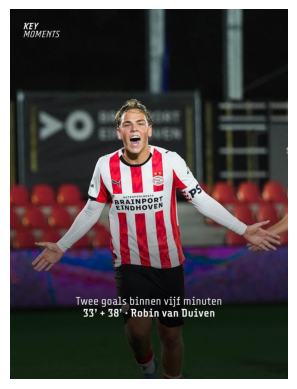

Likes: 6366

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  1


Saved!


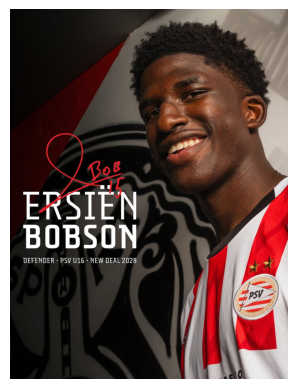

Likes: 6046

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


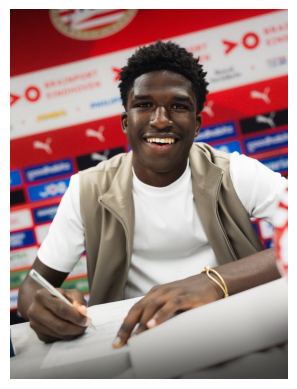

Likes: 6046

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


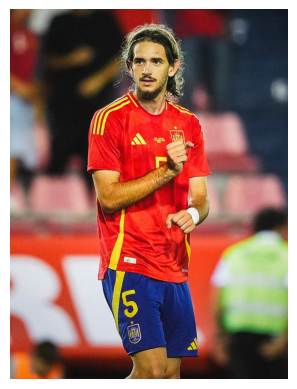

Likes: 8157

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


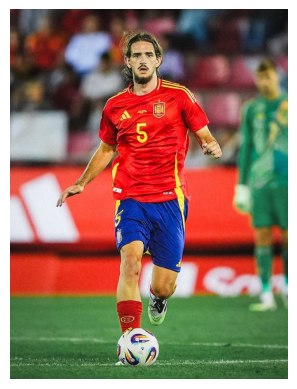

Likes: 8157

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


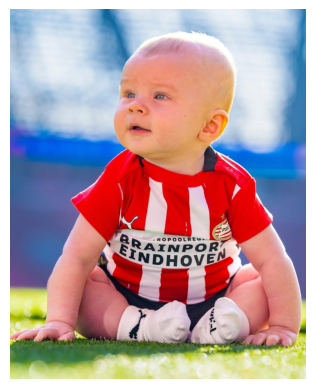

Likes: 8179

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  4


Saved!


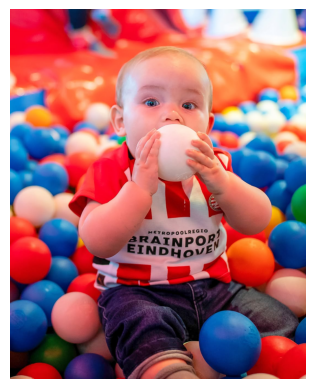

Likes: 8179

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  4


Saved!


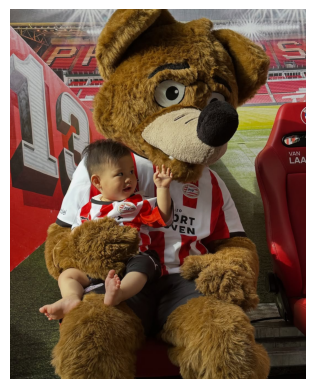

Likes: 8179

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  4


Saved!


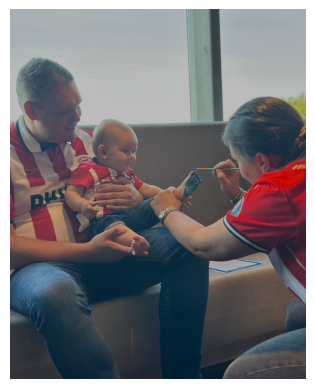

Likes: 8179

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  4


Saved!


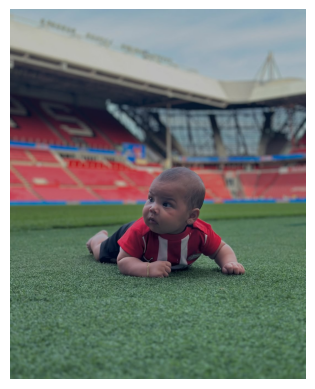

Likes: 8179

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  4


Saved!


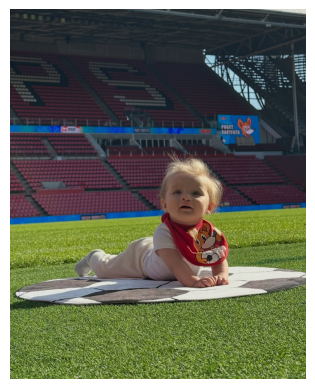

Likes: 8179

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  4


Saved!


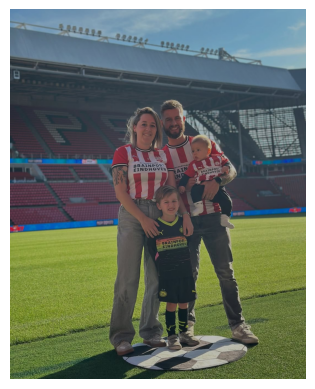

Likes: 8179

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  6


Saved!


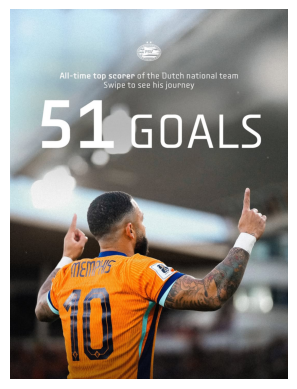

Likes: 16625

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


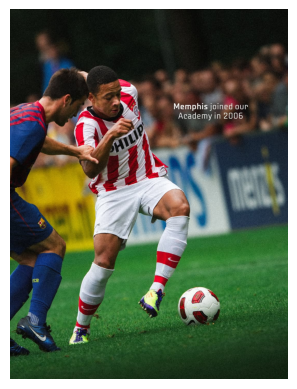

Likes: 16625

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


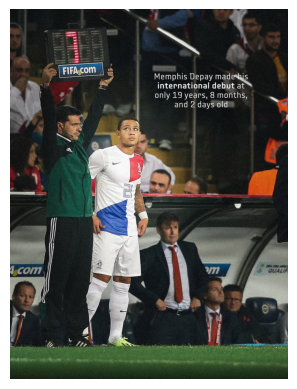

Likes: 16625

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


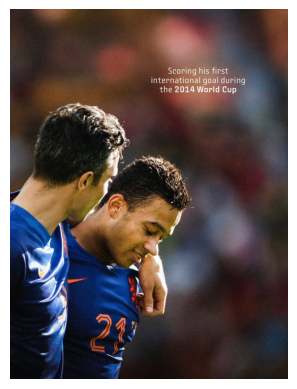

Likes: 16625

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


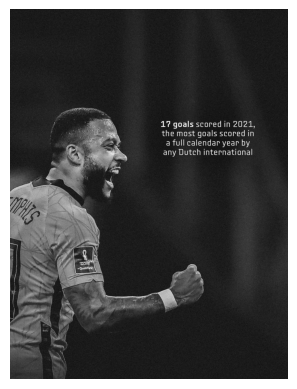

Likes: 16625

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


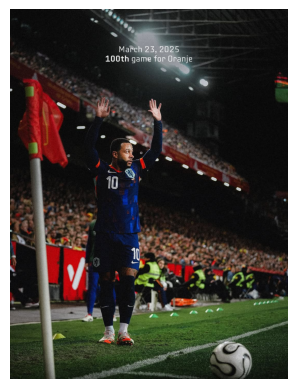

Likes: 16625

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


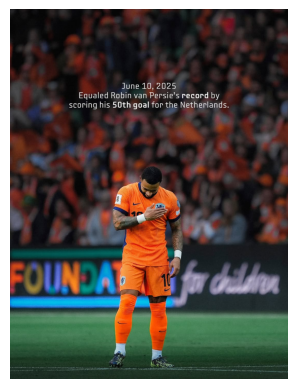

Likes: 16625

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


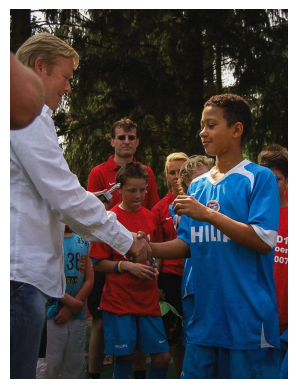

Likes: 92538

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  4


Saved!


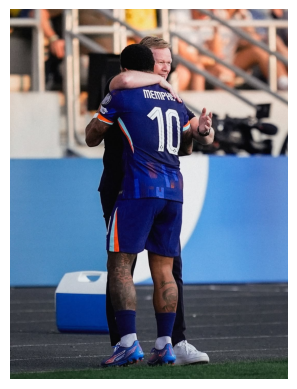

Likes: 92538

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  3


Saved!


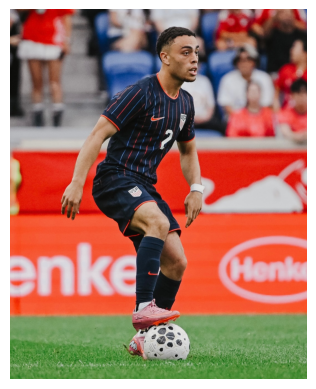

Likes: 5860

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  3


Saved!


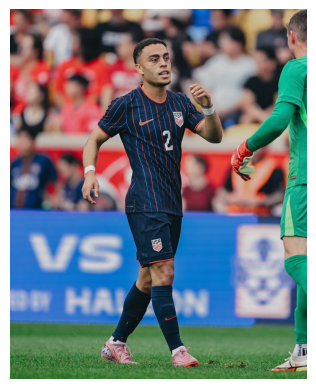

Likes: 5860

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


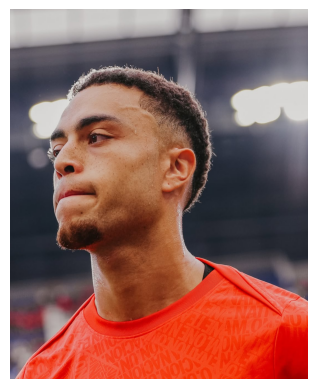

Likes: 5860

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


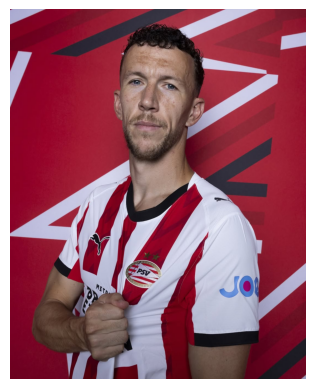

Likes: 127514

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


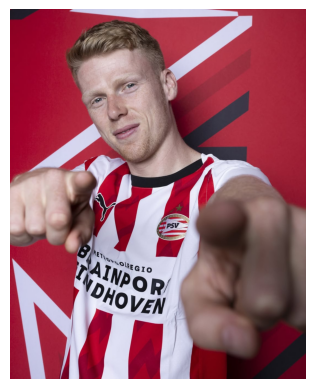

Likes: 127514

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


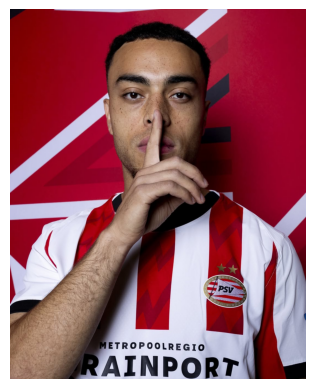

Likes: 127514

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


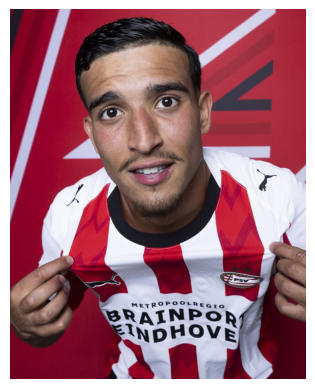

Likes: 127514

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


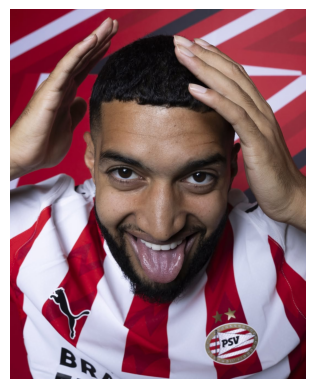

Likes: 127514

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


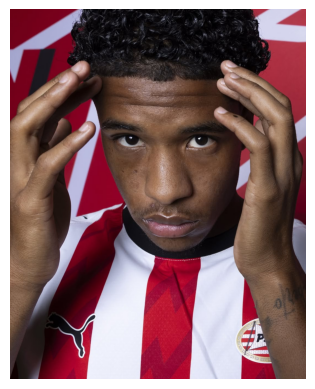

Likes: 127514

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


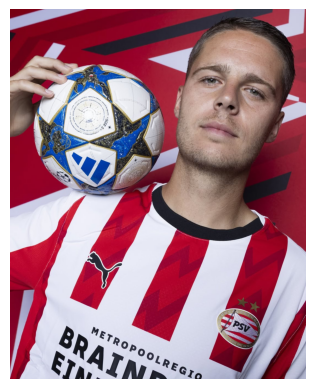

Likes: 127514

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


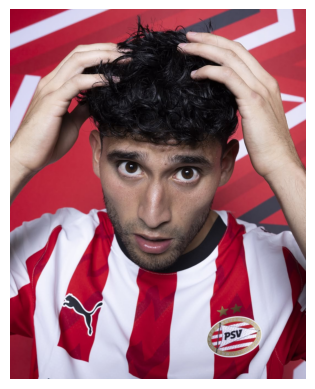

Likes: 127514

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


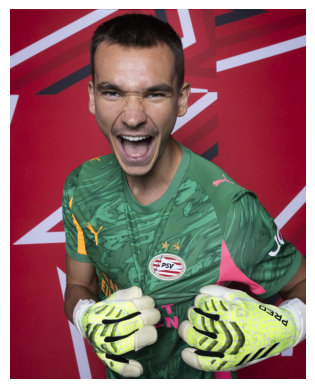

Likes: 127514

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


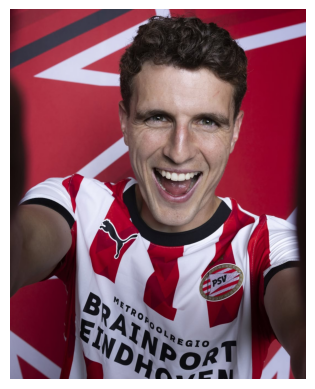

Likes: 127514

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


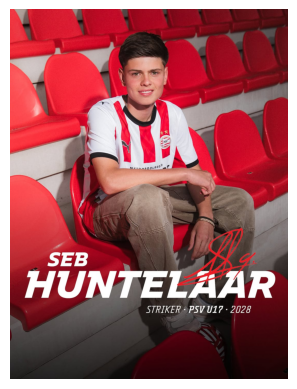

Likes: 26018

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


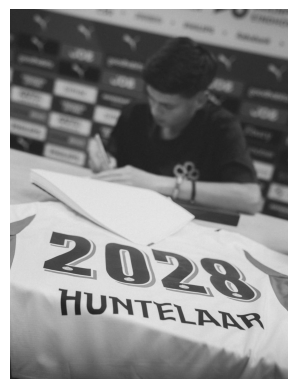

Likes: 26018

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


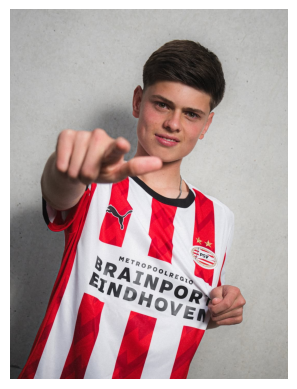

Likes: 26018

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


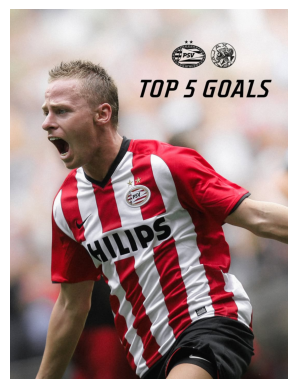

Likes: 18042

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


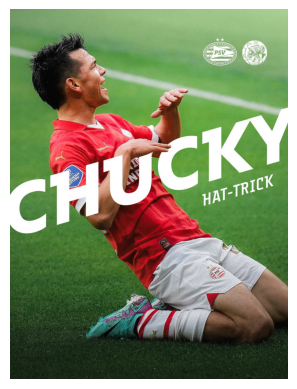

Likes: 23567

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


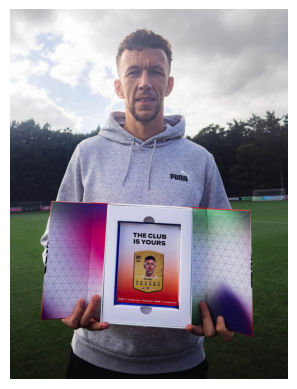

Likes: 7139

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


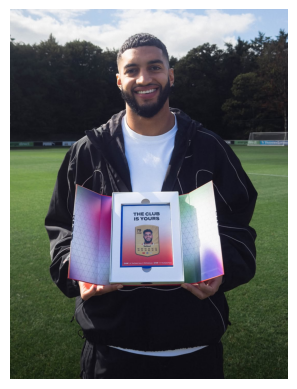

Likes: 7139

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


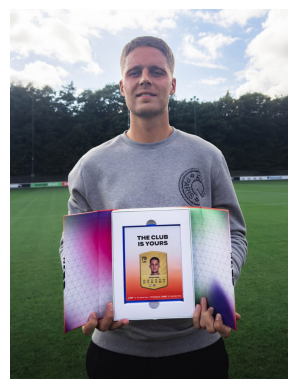

Likes: 7139

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


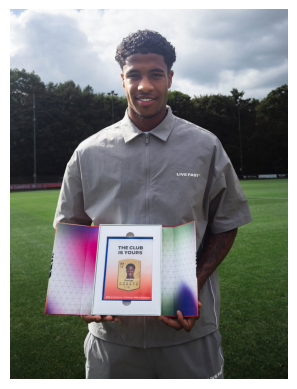

Likes: 7139

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


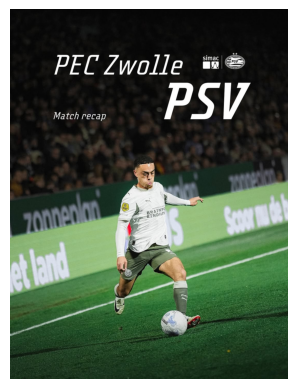

Likes: 3890

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


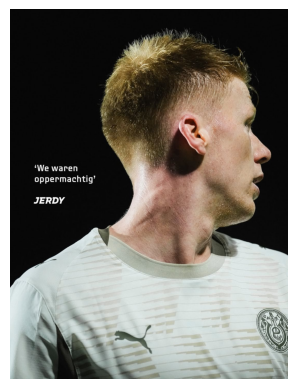

Likes: 3890

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


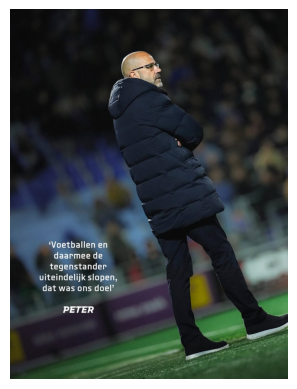

Likes: 3890

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


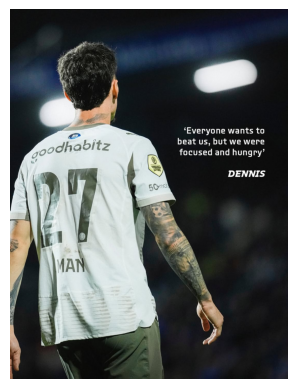

Likes: 3890

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


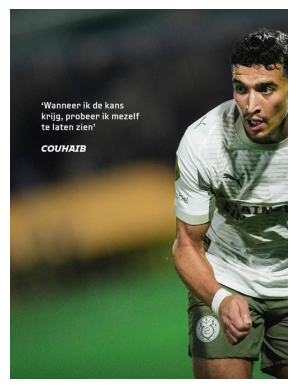

Likes: 3890

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


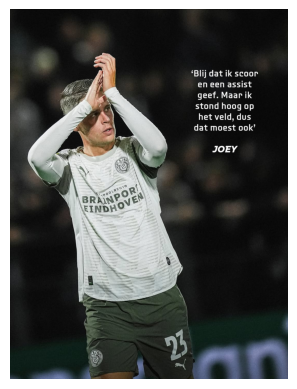

Likes: 3890

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


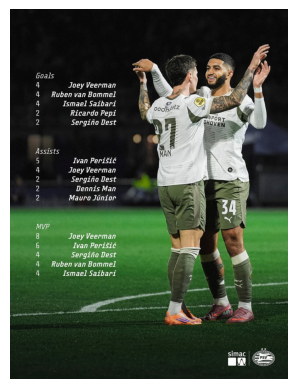

Likes: 3890

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


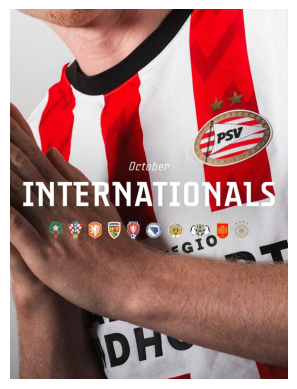

Likes: 9585

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


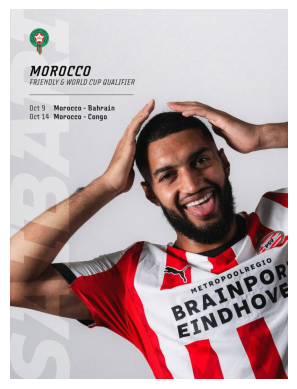

Likes: 9585

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


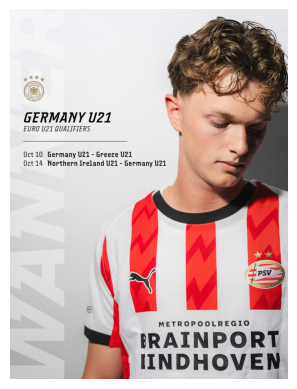

Likes: 9585

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


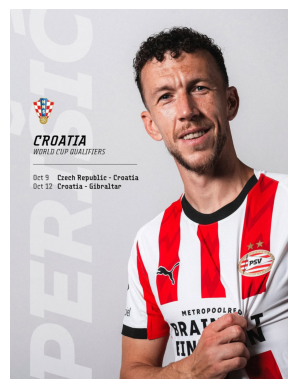

Likes: 9585

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


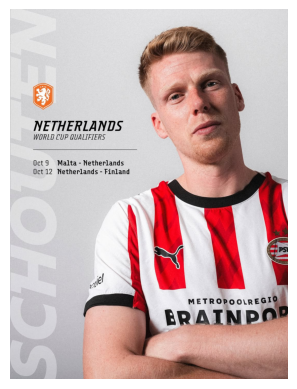

Likes: 9585

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


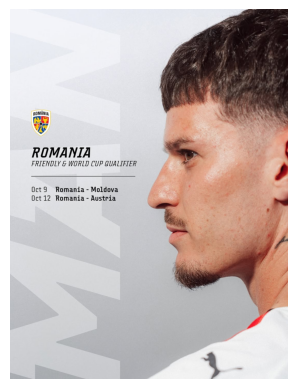

Likes: 9585

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


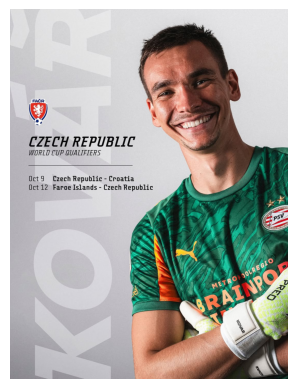

Likes: 9585

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


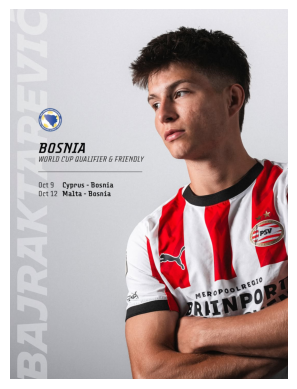

Likes: 9585

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


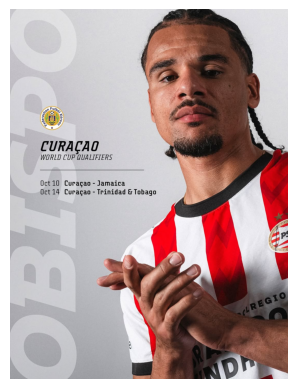

Likes: 9585

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


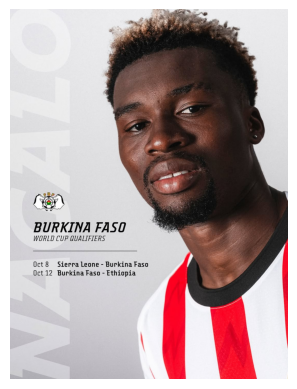

Likes: 9585

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


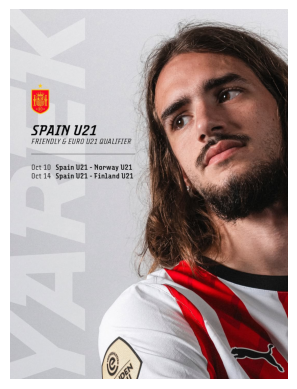

Likes: 9585

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


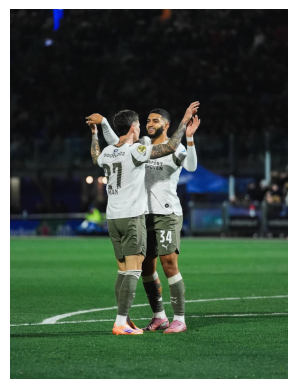

Likes: 6865

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  1


Saved!


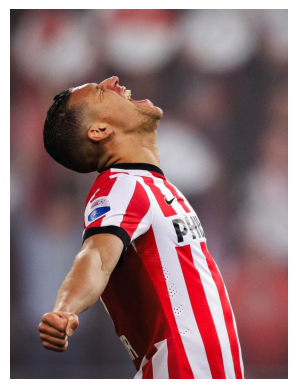

Likes: 9473

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


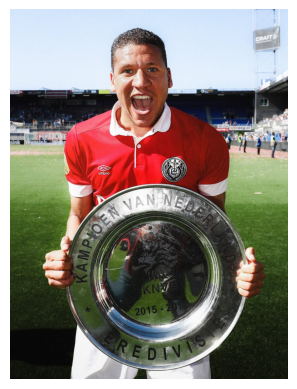

Likes: 9473

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


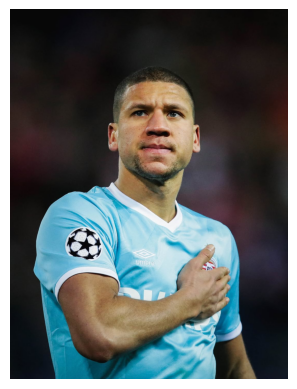

Likes: 9473

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


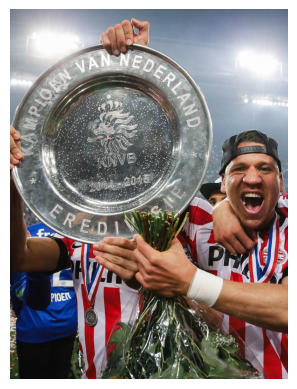

Likes: 9473

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


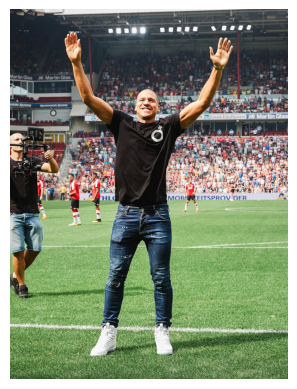

Likes: 9473

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


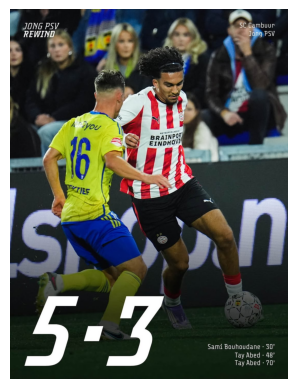

Likes: 6625

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


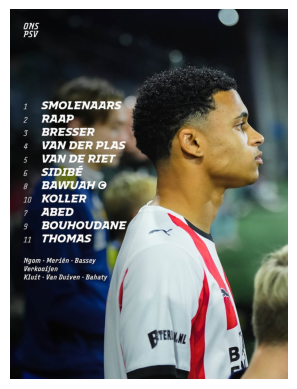

Likes: 6625

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


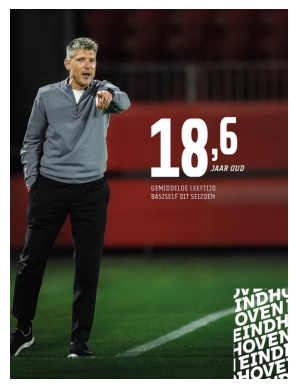

Likes: 6625

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


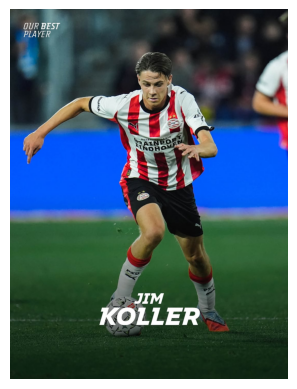

Likes: 6625

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


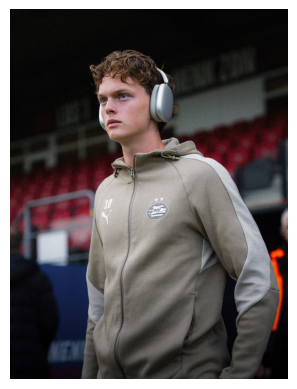

Likes: 4316

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


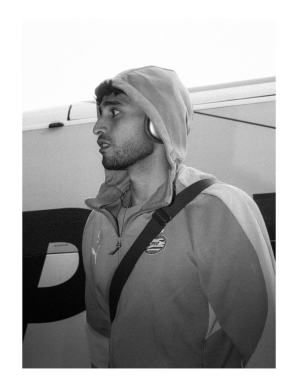

Likes: 4316

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


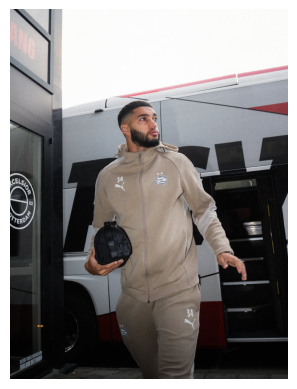

Likes: 4316

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


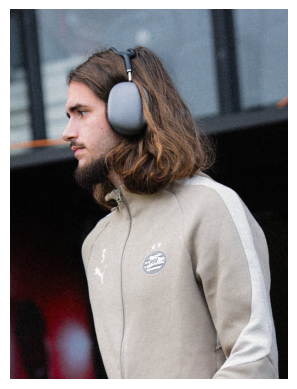

Likes: 4316

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


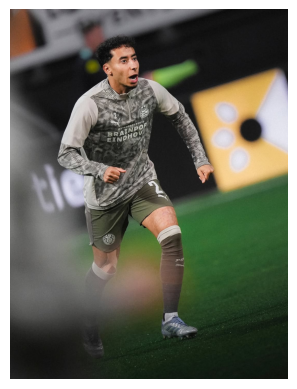

Likes: 4147

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


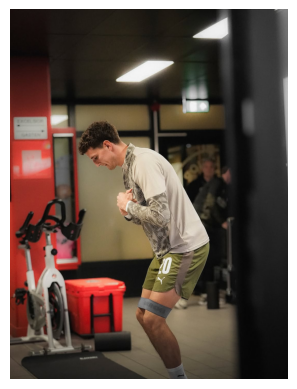

Likes: 4147

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  3


Saved!


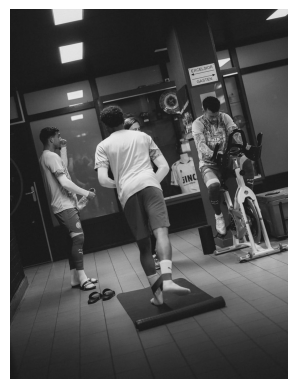

Likes: 4147

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  3


Saved!


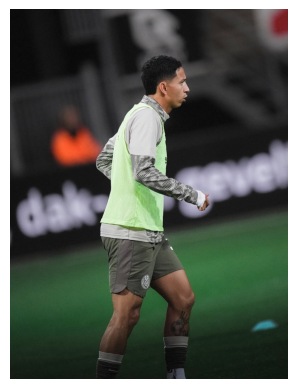

Likes: 4147

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  


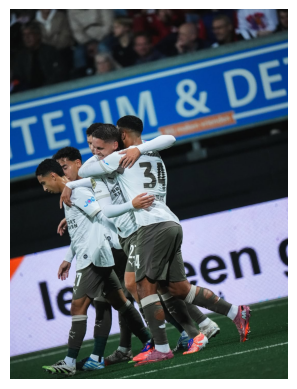

Likes: 5776

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  1


Saved!


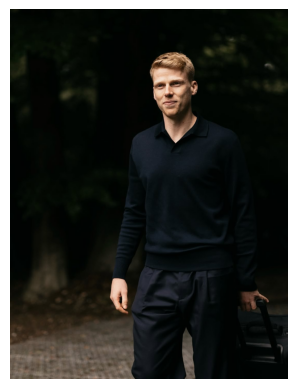

Likes: 4803

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


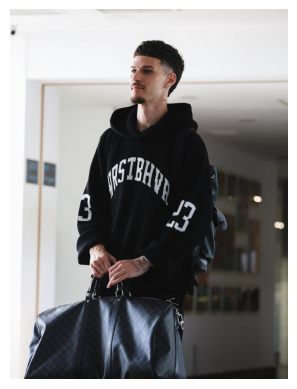

Likes: 4803

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


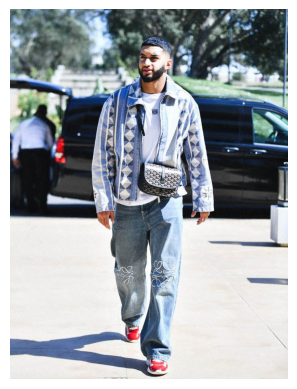

Likes: 4803

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


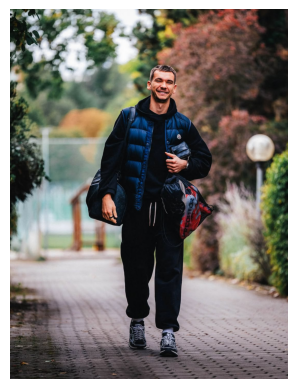

Likes: 4803

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


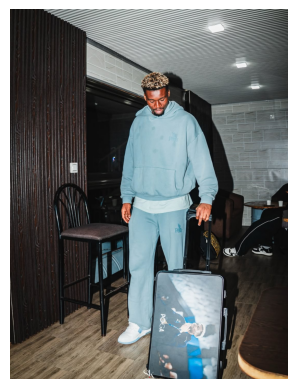

Likes: 4803

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


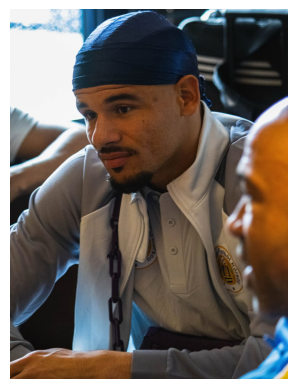

Likes: 4803

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


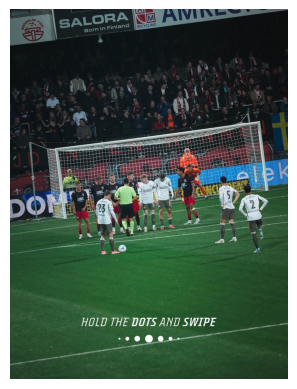

Likes: 10441

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


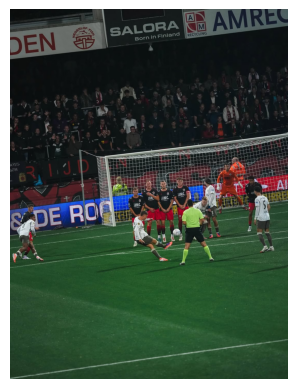

Likes: 10441

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  0


Saved!


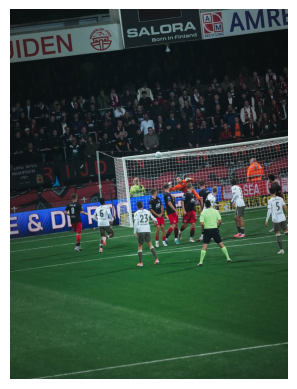

Likes: 10441

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  0


Saved!


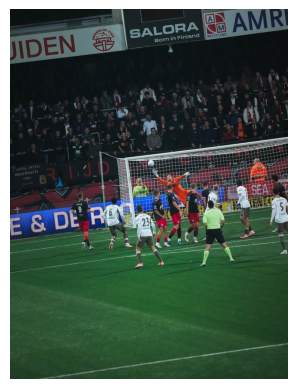

Likes: 10441

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  0


Saved!


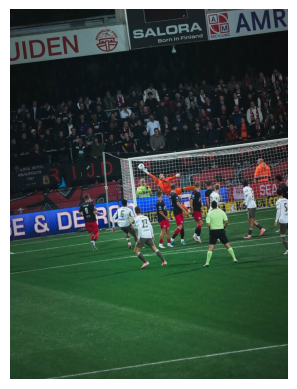

Likes: 10441

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  0


Saved!


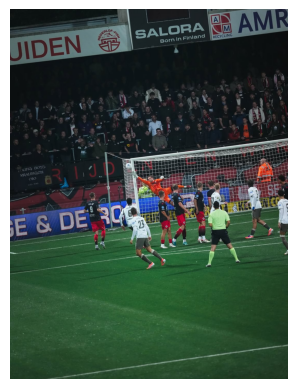

Likes: 10441

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  0


Saved!


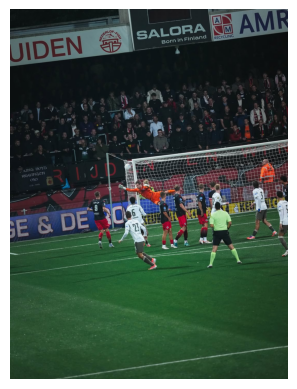

Likes: 10441

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  0


Saved!


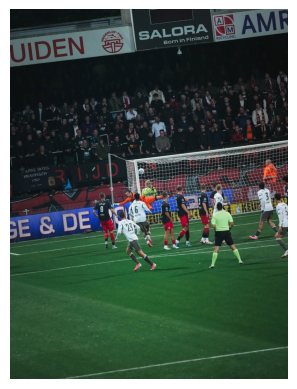

Likes: 10441

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  0


Saved!


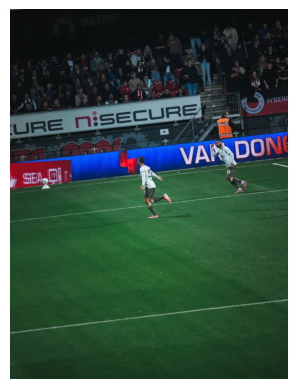

Likes: 10441

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  1


Saved!


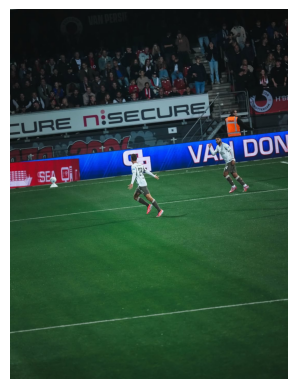

Likes: 10441

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  1


Saved!


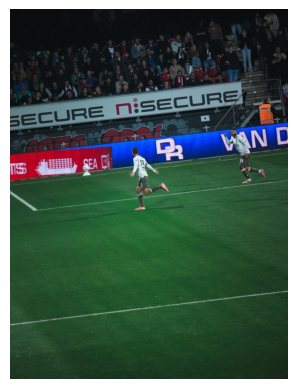

Likes: 10441

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  1


Saved!


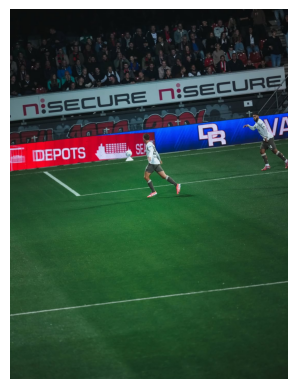

Likes: 10441

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  1


Saved!


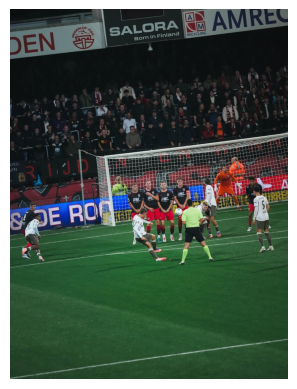

Likes: 10441

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  0


Saved!


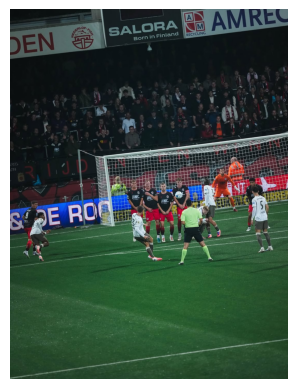

Likes: 10441

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  0


Saved!


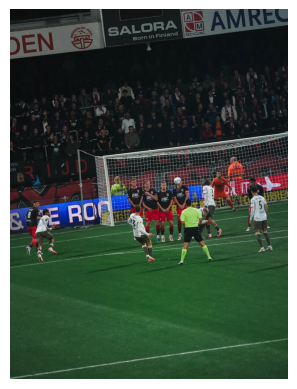

Likes: 10441

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  0


Saved!


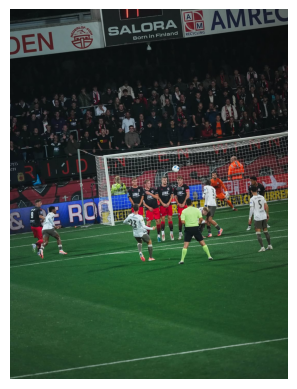

Likes: 10441

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  0


Saved!


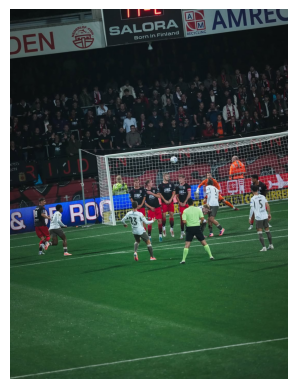

Likes: 10441

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  0


Saved!


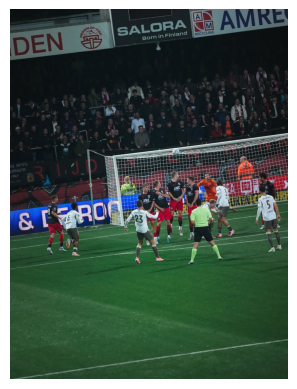

Likes: 10441

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  0


Saved!


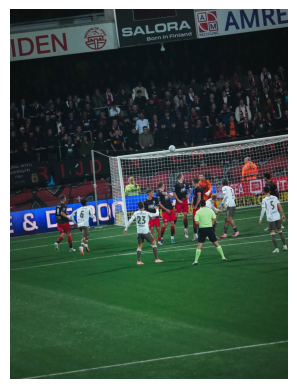

Likes: 10441

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  0


Saved!


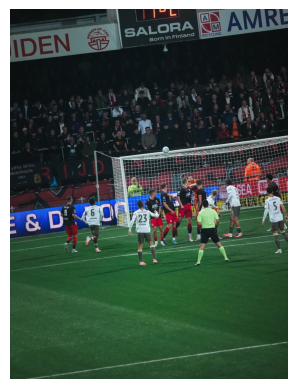

Likes: 10441

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  0


Saved!


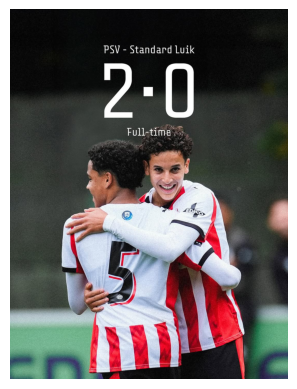

Likes: 6720

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


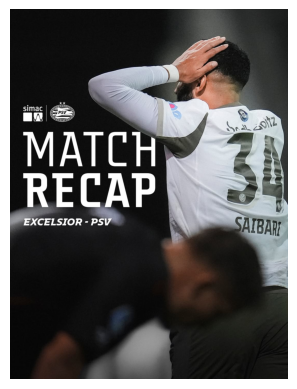

Likes: 2616

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


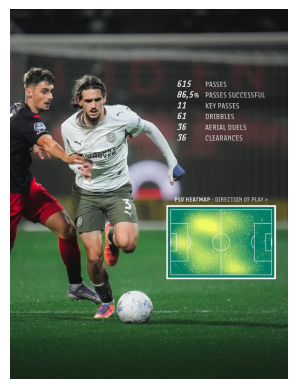

Likes: 2616

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


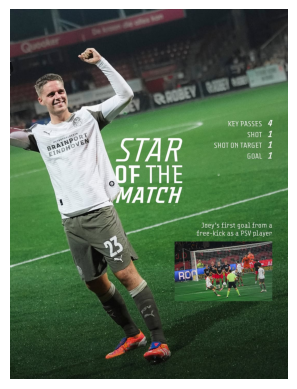

Likes: 2616

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


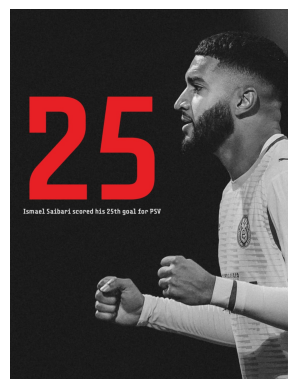

Likes: 2616

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


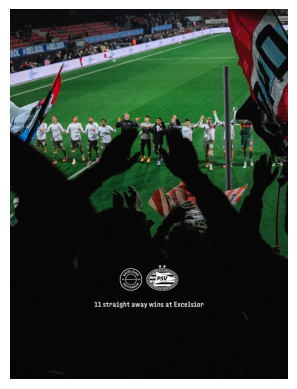

Likes: 2616

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


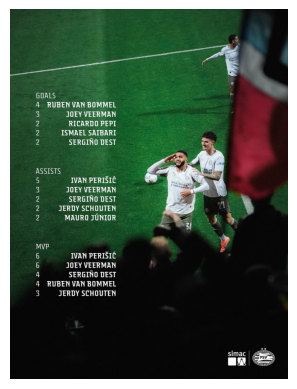

Likes: 2616

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


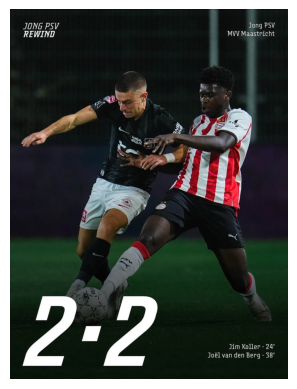

Likes: 4300

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


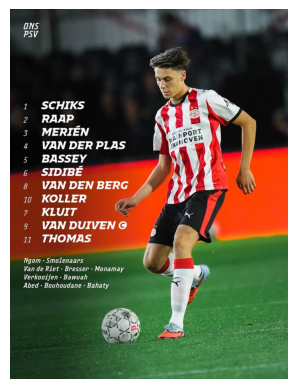

Likes: 4300

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


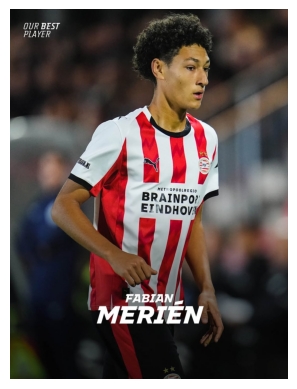

Likes: 4300

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


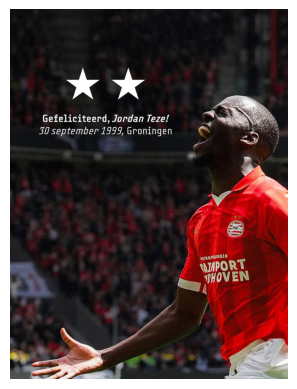

Likes: 9250

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


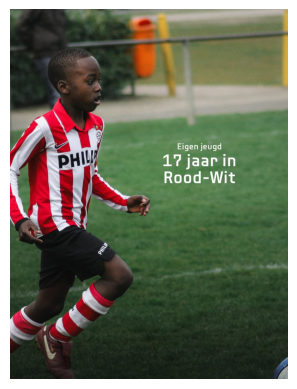

Likes: 9250

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


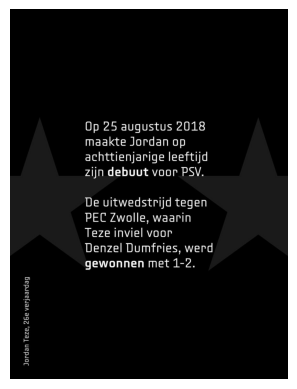

Likes: 9250

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


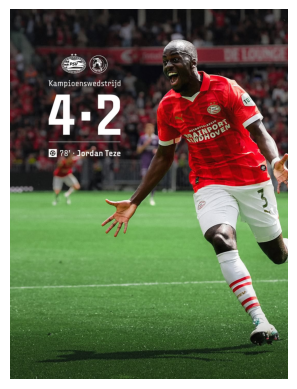

Likes: 9250

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


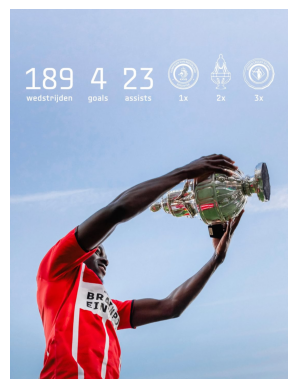

Likes: 9250

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


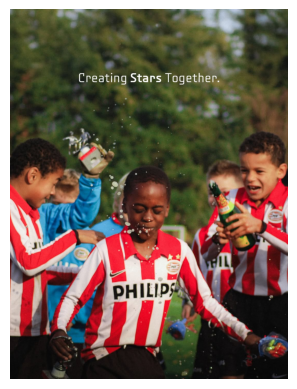

Likes: 9250

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


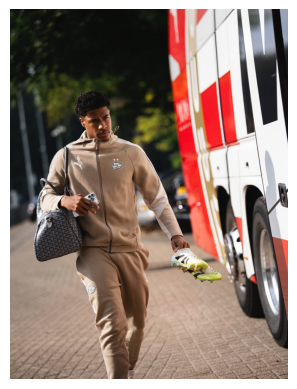

Likes: 8505

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


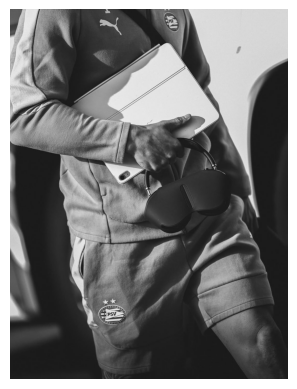

Likes: 8505

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


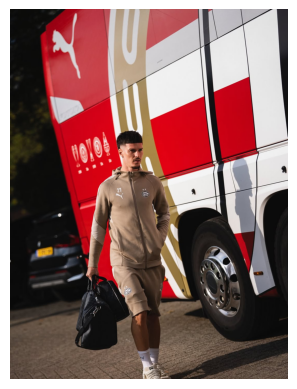

Likes: 8505

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


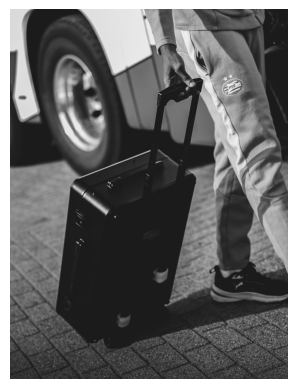

Likes: 8505

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


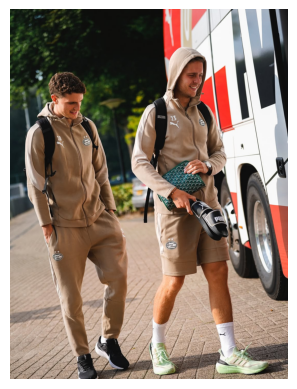

Likes: 8505

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


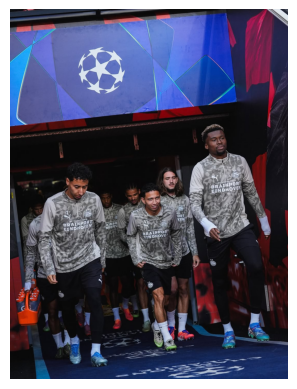

Likes: 8792

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  0


Saved!


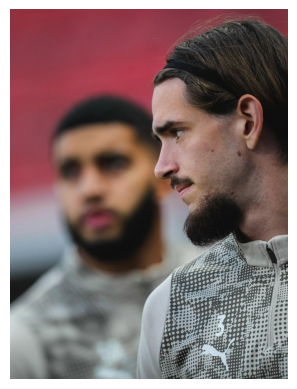

Likes: 8792

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


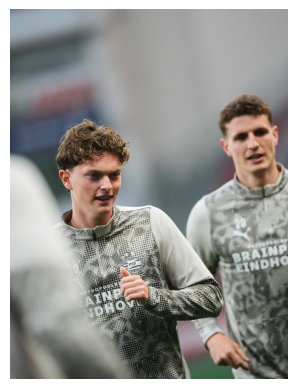

Likes: 8792

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


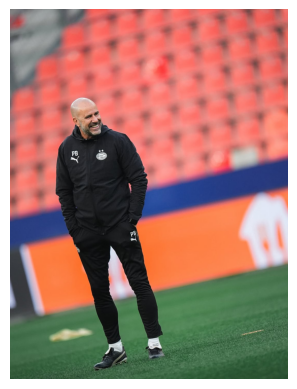

Likes: 8792

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


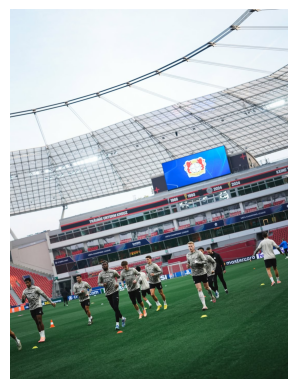

Likes: 8792

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  3


Saved!


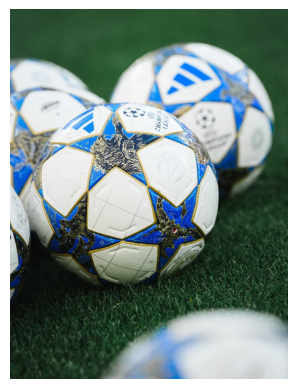

Likes: 8792

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  6


Saved!


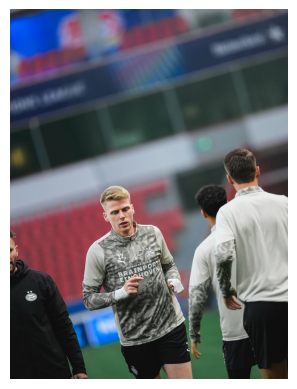

Likes: 8792

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


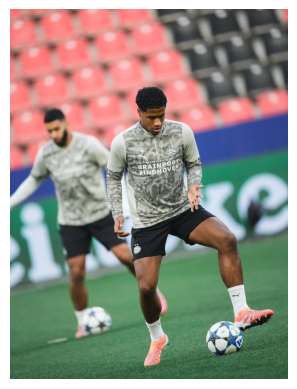

Likes: 8792

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  3


Saved!


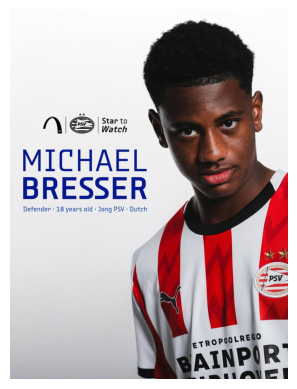

Likes: 4004

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


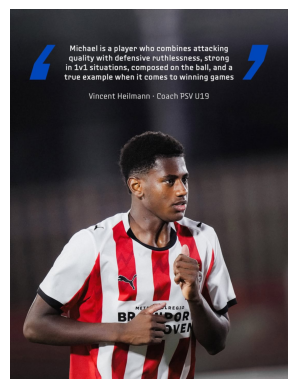

Likes: 4004

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


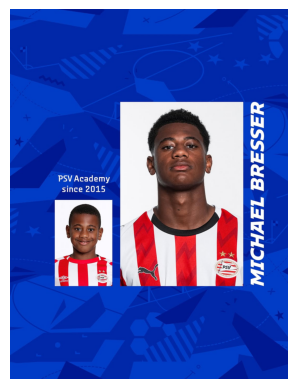

Likes: 4004

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


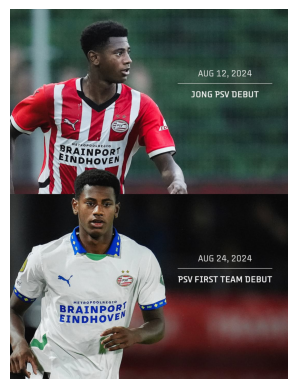

Likes: 4004

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


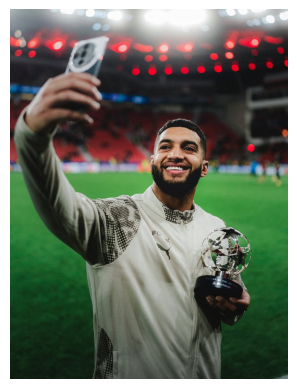

Likes: 157626

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


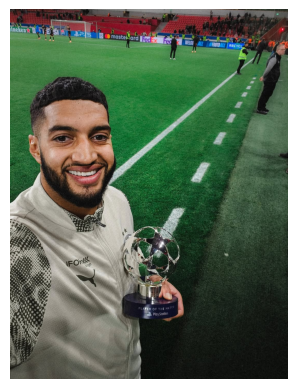

Likes: 157626

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


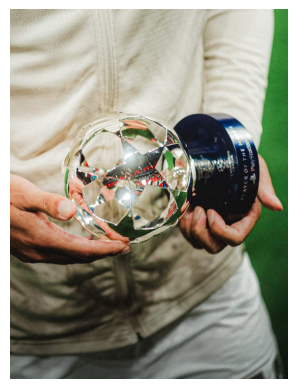

Likes: 157626

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  1


Saved!


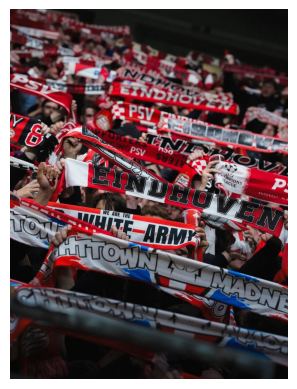

Likes: 8220

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  4


Saved!


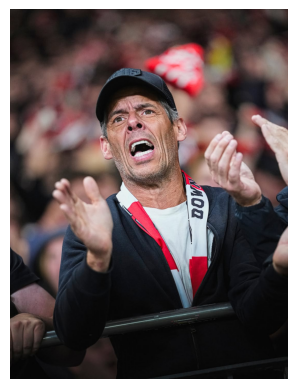

Likes: 8220

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  4


Saved!


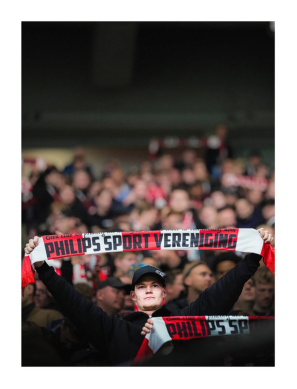

Likes: 8220

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  4


Saved!


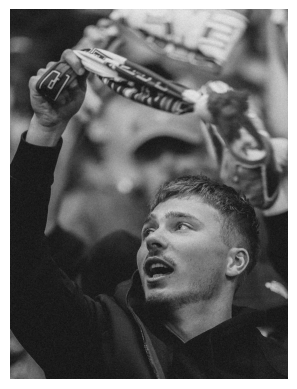

Likes: 8220

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  4


Saved!


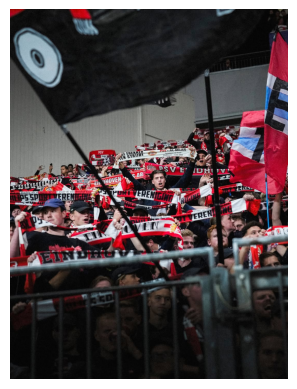

Likes: 8220

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  4


Saved!


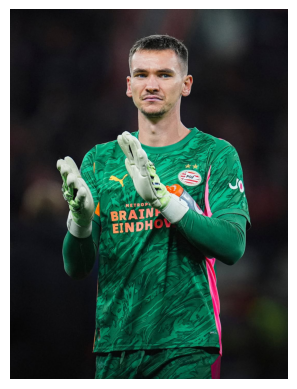

Likes: 14550

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


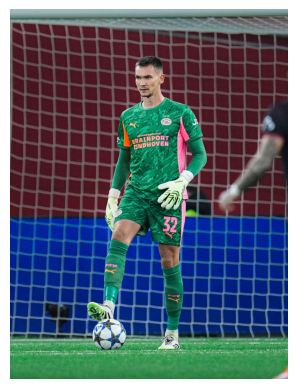

Likes: 14550

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


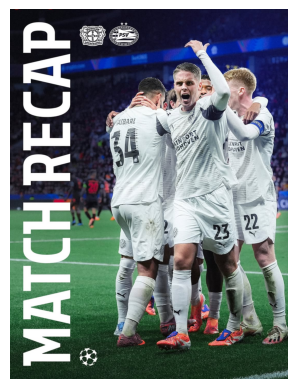

Likes: 5871

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


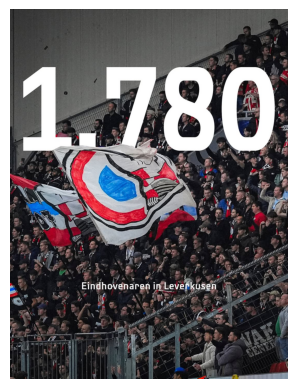

Likes: 5871

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


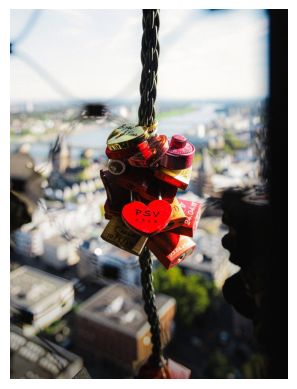

Likes: 5871

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  6


Saved!


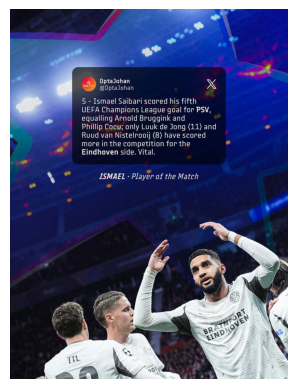

Likes: 5871

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


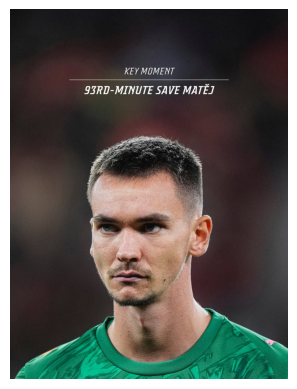

Likes: 5871

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


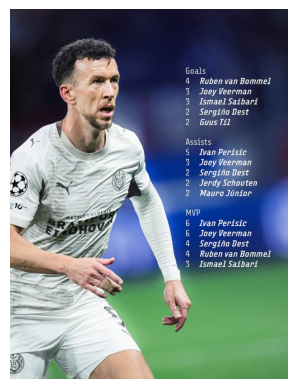

Likes: 5871

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


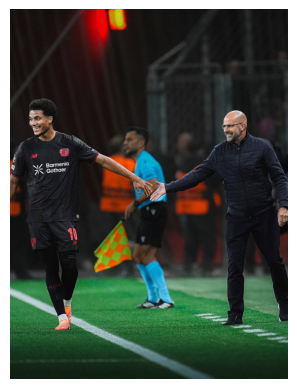

Likes: 37034

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  0


Saved!


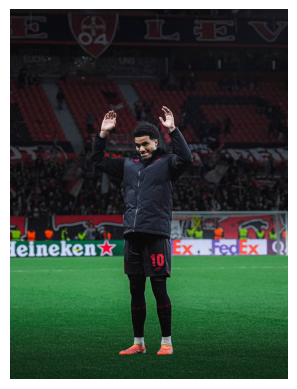

Likes: 37034

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


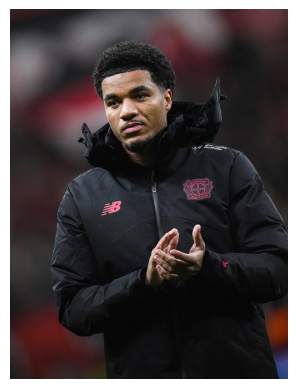

Likes: 37034

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


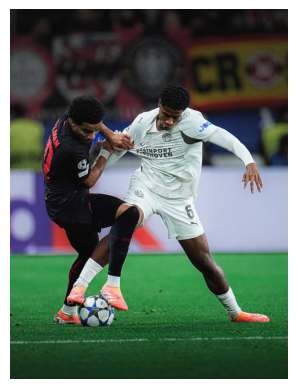

Likes: 37034

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  0


Saved!


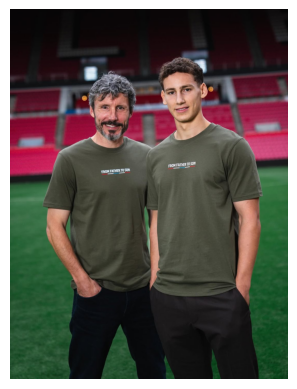

Likes: 14731

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


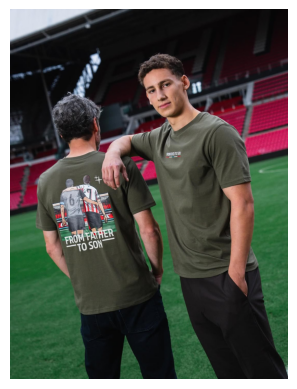

Likes: 14731

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  7


Saved!


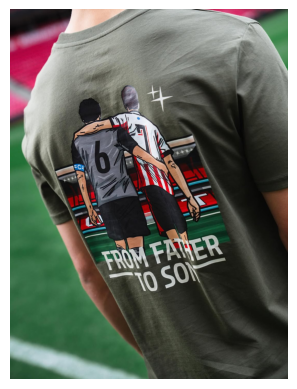

Likes: 14731

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  7


Saved!


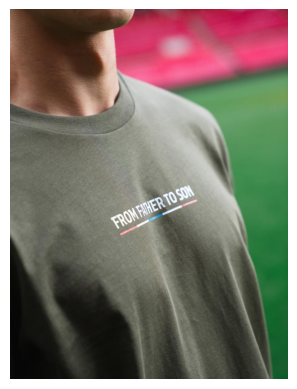

Likes: 14731

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  7


Saved!


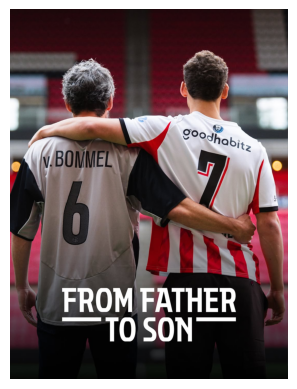

Likes: 11497

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


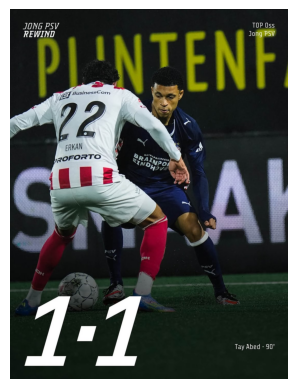

Likes: 4194

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


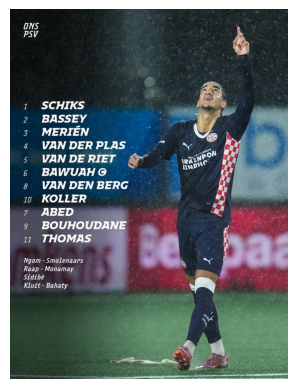

Likes: 4194

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


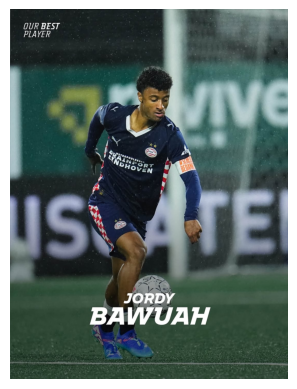

Likes: 4194

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


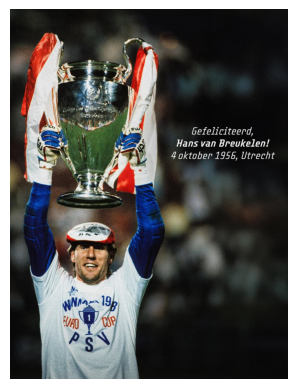

Likes: 3131

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


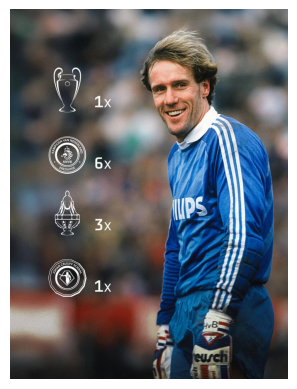

Likes: 3131

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


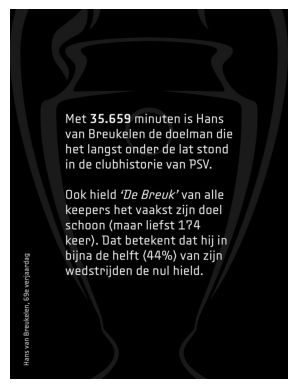

Likes: 3131

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


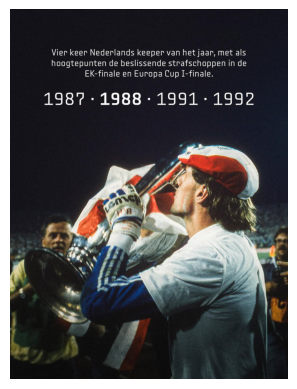

Likes: 3131

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


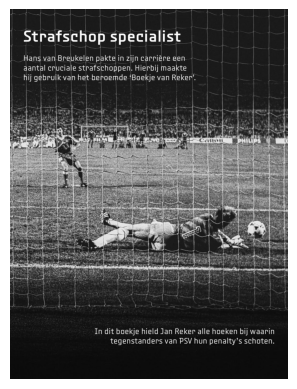

Likes: 3131

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  5


Saved!


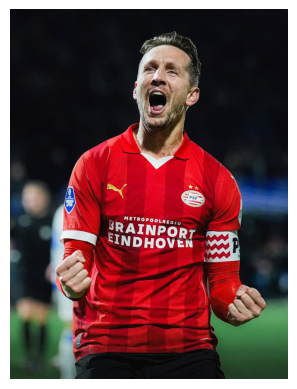

Likes: 6279

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


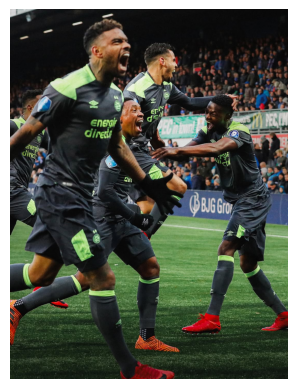

Likes: 6279

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  1


Saved!


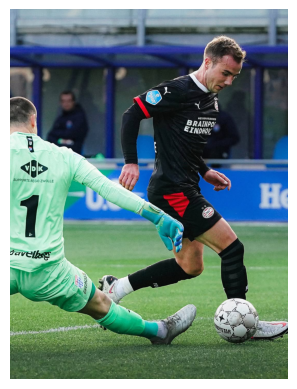

Likes: 6279

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  0


Saved!


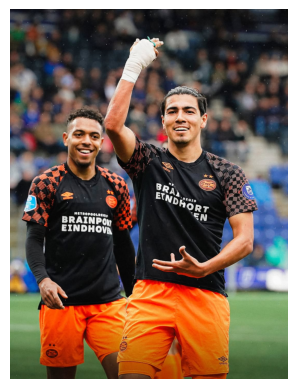

Likes: 6279

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  1


Saved!


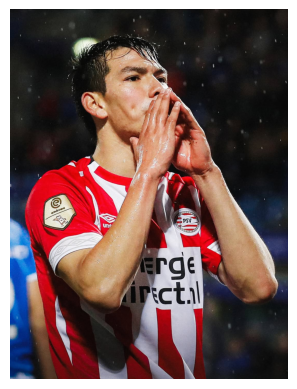

Likes: 6279

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


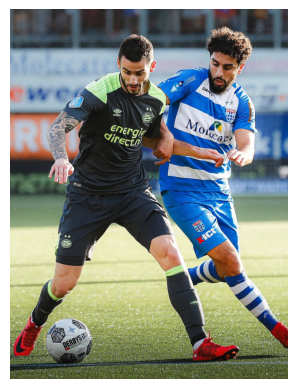

Likes: 6279

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  0


Saved!


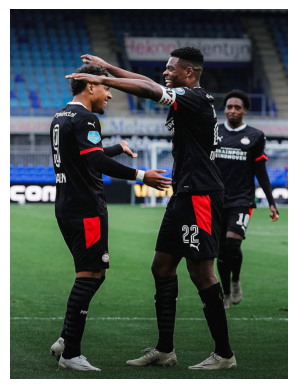

Likes: 6279

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  1


Saved!


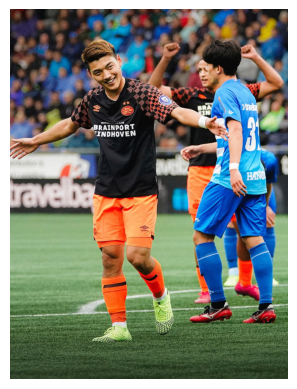

Likes: 6279

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  1


Saved!


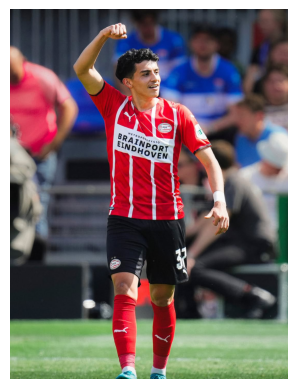

Likes: 6279

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  1


Saved!


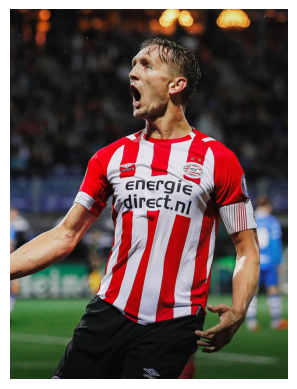

Likes: 6279

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  1


Saved!


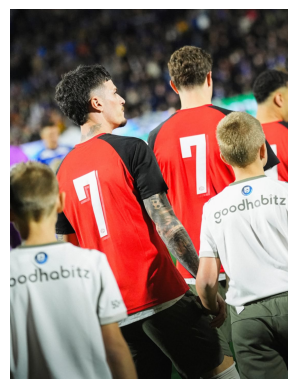

Likes: 9961

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


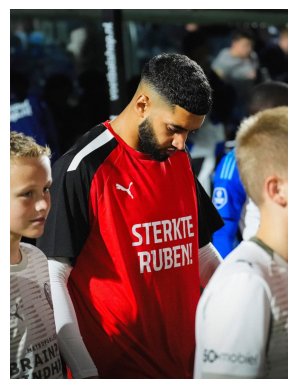

Likes: 9961

Categories:
0: match_action
1: celebration
2: player_portrait
3: training
4: fans_stadium
5: graphic_post
6: behind_scenes
7: commercial


Select category number:  2


Saved!


In [18]:
##### from PIL import Image
import matplotlib.pyplot as plt
import os
import pandas as pd

for idx, row in final_df.iterrows():

    if pd.isna(row["category"]):

        image_path = os.path.join(
            "raw_images",
            row["image_path"]
        )

        # 🔥 comprobar si existe
        if not os.path.exists(image_path):

            print(f"Missing image: {image_path}")

            continue

        try:

            img = Image.open(image_path)

            plt.imshow(img)
            plt.axis("off")
            plt.show()

            print("Likes:", row["likes"])

            print("\nCategories:")

            for i, c in enumerate(categories):
                print(f"{i}: {c}")

            choice = input("Select category number: ")

            if choice.isdigit():

                final_df.loc[idx, "category"] = categories[int(choice)]

                final_df.to_csv(
                    "labeled_dataset.csv",
                    index=False
                )

                print("Saved!")

        except Exception as e:

            print(f"Error loading image: {e}")
 